# Adaptive FAQ Recommendation

FAQ answers are ranked using TF-IDF, cosine similarity, and user feedback.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
from collections import Counter

In [ ]:
faqs = [
    # 1. Accounts (20 FAQs)
    ["How do I reset my password?", "Click Forgot Password on the login page and follow the email instructions.", "Accounts"],
    ["How do I create a new account?", "Click Sign Up, enter your details, and verify your email address.", "Accounts"],
    ["Why can I not log in?", "Check your email and password, and reset your password if needed.", "Accounts"],
    ["How do I change my email address?", "Open Account Settings and update your email address.", "Accounts"],
    ["How do I change my username?", "Open Account Settings to see whether your username can be edited.", "Accounts"],
    ["How do I update my profile information?", "Go to Account Settings, edit your details, and save the changes.", "Accounts"],
    ["Why is my account locked?", "Follow the account recovery instructions or contact customer support.", "Accounts"],
    ["How do I verify my email address?", "Open the verification email and click the link provided.", "Accounts"],
    ["How do I delete my account?", "Check Account Settings for account deletion options or contact support.", "Accounts"],
    ["How do I change my account password?", "Open Security Settings and choose Change Password.", "Accounts"],
    ["Can I use the same email for two accounts?", "Check the registration rules; many services require a unique email address.", "Accounts"],
    ["What should I do if I forget my username?", "Check your registration email or use the account recovery option.", "Accounts"],
    ["How do I enable two-factor authentication?", "Open Security Settings and follow the instructions to enable two-factor authentication.", "Accounts"],
    ["How do I disable two-factor authentication?", "Open Security Settings and follow the available verification steps.", "Accounts"],
    ["Why am I not receiving a verification email?", "Check your spam folder, confirm your email address, and request another email.", "Accounts"],
    ["How do I recover a hacked account?", "Reset your password immediately and contact support if you cannot access your account.", "Accounts"],
    ["Can I change my registered phone number?", "Open Account Settings and update your phone number if the option is available.", "Accounts"],
    ["How do I sign out of my account?", "Open your profile menu and select Log Out.", "Accounts"],
    ["How do I update my security settings?", "Open the Security section in Account Settings and save your changes.", "Accounts"],
    ["Why does my session keep expiring?", "Sign in again and check your browser settings or internet connection.", "Accounts"],

    # 2. Orders (20 FAQs)
    ["How do I track my order?", "Open My Orders to check the latest delivery status.", "Orders"],
    ["How do I cancel an order?", "Open My Orders and select Cancel Order if it is available.", "Orders"],
    ["Can I change an order after placing it?", "Contact support quickly to check whether the order can still be changed.", "Orders"],
    ["How do I find my order number?", "Open My Orders and select the order to view its details.", "Orders"],
    ["How do I view my order history?", "Open the My Orders section of your account.", "Orders"],
    ["How do I confirm that my order was placed?", "Check your order history and confirmation email.", "Orders"],
    ["Why did I receive an order confirmation twice?", "Check whether duplicate orders were created and contact support if necessary.", "Orders"],
    ["Can I place an order without creating an account?", "Check whether guest checkout is available on the checkout page.", "Orders"],
    ["How do I reorder a previous purchase?", "Open your order history and select the reorder option if available.", "Orders"],
    ["How do I change the items in my order?", "Contact support as soon as possible before the order is processed.", "Orders"],
    ["Why was my order cancelled?", "Check your email for the cancellation reason or contact customer support.", "Orders"],
    ["How do I check my order status?", "Open My Orders to see whether your order is processing, shipped, or delivered.", "Orders"],
    ["Can I combine two orders?", "Contact support to check whether the orders can be combined.", "Orders"],
    ["How do I request a duplicate invoice?", "Open the completed order and download the invoice again, or contact support.", "Orders"],
    ["What does order processing mean?", "It means your order is being prepared before shipment.", "Orders"],
    ["What does shipped mean?", "It means your order has been dispatched to the delivery service.", "Orders"],
    ["What does delivered mean?", "It means the delivery service has marked your order as delivered.", "Orders"],
    ["Can I cancel an order that has shipped?", "Check the cancellation policy or contact support about return options.", "Orders"],
    ["What should I do if an item is missing from my order?", "Contact support with your order number and details of the missing item.", "Orders"],
    ["How do I report an incorrect order?", "Contact support and provide your order number and the details of the incorrect item.", "Orders"],

    # 3. Payments and Refunds (20 FAQs)
    ["How do I request a refund?", "Open your order details and submit a refund request.", "Payments and Refunds"],
    ["When will I receive my refund?", "Refund timing depends on the payment method and is shown in the refund confirmation.", "Payments and Refunds"],
    ["Why is my payment failing?", "Check your payment details, available balance, and internet connection.", "Payments and Refunds"],
    ["Which payment methods are accepted?", "Available payment methods are listed at checkout.", "Payments and Refunds"],
    ["How do I download an invoice?", "Open a completed order and select Download Invoice.", "Payments and Refunds"],
    ["How do I apply a discount code?", "Enter your discount code in the coupon box before placing your order.", "Payments and Refunds"],
    ["How do I remove a saved payment method?", "Open your account's payment settings and remove the saved method.", "Payments and Refunds"],
    ["Why was I charged twice?", "Check your transaction history and contact support if duplicate charges remain.", "Payments and Refunds"],
    ["Can I pay using a debit card?", "Check the payment methods listed at checkout.", "Payments and Refunds"],
    ["Can I pay using a credit card?", "Choose the credit card option at checkout if it is available.", "Payments and Refunds"],
    ["Can I pay using UPI?", "Select UPI at checkout if the payment option is supported.", "Payments and Refunds"],
    ["Why was my discount code rejected?", "Check the code's expiry date, minimum order value, and eligibility conditions.", "Payments and Refunds"],
    ["Can I use two discount codes together?", "Check the promotion terms to see whether multiple codes can be combined.", "Payments and Refunds"],
    ["How do I check my refund status?", "Open your order details or refund confirmation to review the status.", "Payments and Refunds"],
    ["Why has my refund not arrived?", "Check the stated refund timeline and contact support if it has passed.", "Payments and Refunds"],
    ["Can I get a refund for a cancelled order?", "Check the cancellation and refund policy for your order.", "Payments and Refunds"],
    ["How do I update my billing address?", "Open your billing or account settings and update the address.", "Payments and Refunds"],
    ["Why is my transaction pending?", "Wait for the payment status to update and check with your payment provider if necessary.", "Payments and Refunds"],
    ["How do I download a payment receipt?", "Open your order or transaction details and look for the receipt option.", "Payments and Refunds"],
    ["Is cash on delivery available?", "Check whether cash on delivery appears among the options at checkout.", "Payments and Refunds"],

    # 4. Delivery and Shipping (20 FAQs)
    ["How long does delivery take?", "The estimated delivery date is shown in your order details.", "Delivery and Shipping"],
    ["What should I do if my order is late?", "Check the tracking details and contact support if the order is delayed.", "Delivery and Shipping"],
    ["How do I change my delivery address?", "Open your order details and edit the address if the order has not shipped.", "Delivery and Shipping"],
    ["How much does shipping cost?", "The shipping charge is displayed during checkout.", "Delivery and Shipping"],
    ["Do you offer free delivery?", "Check the delivery terms for any free-shipping eligibility.", "Delivery and Shipping"],
    ["How can I track a shipment?", "Use the tracking link in your order details or dispatch email.", "Delivery and Shipping"],
    ["Why is my tracking information not updating?", "Tracking may take time to refresh after dispatch; check again later.", "Delivery and Shipping"],
    ["Can I schedule a delivery?", "Check the delivery options during checkout or contact support.", "Delivery and Shipping"],
    ["Can I change my delivery date?", "Check your order's delivery options or contact the delivery provider.", "Delivery and Shipping"],
    ["What happens if I miss the delivery?", "Check the tracking page for another attempt or instructions from the courier.", "Delivery and Shipping"],
    ["Can I collect my order in person?", "Check whether pickup or collection options are offered for your order.", "Delivery and Shipping"],
    ["Why is my order stuck in transit?", "Check the tracking details and contact support if there is no progress.", "Delivery and Shipping"],
    ["Do you deliver to my location?", "Enter your postal code at checkout to check delivery availability.", "Delivery and Shipping"],
    ["How do I contact the delivery partner?", "Check your tracking page or dispatch email for the courier's contact details.", "Delivery and Shipping"],
    ["Can I change my phone number for delivery?", "Contact support before delivery to check whether the number can be updated.", "Delivery and Shipping"],
    ["What does out for delivery mean?", "It means the package is with the delivery agent for delivery that day.", "Delivery and Shipping"],
    ["Why was delivery attempted but not completed?", "Check the courier's update and follow the instructions for another attempt.", "Delivery and Shipping"],
    ["How do I report a lost package?", "Contact support with your order number and tracking information.", "Delivery and Shipping"],
    ["Can I request contactless delivery?", "Check the available delivery instructions or options for your order.", "Delivery and Shipping"],
    ["How do I confirm my delivery address?", "Open your order details and verify the address shown there.", "Delivery and Shipping"],

    # 5. Products and Returns (20 FAQs)
    ["How do I check product availability?", "Open the product page to see whether the item is in stock.", "Products and Returns"],
    ["How do I return a product?", "Open your order details and follow the return instructions.", "Products and Returns"],
    ["How do I report a damaged product?", "Contact support with your order number and details of the damage.", "Products and Returns"],
    ["How do I exchange a product?", "Check the exchange policy and follow the instructions in your order details.", "Products and Returns"],
    ["Can I return a product without its original packaging?", "Check the return policy because packaging requirements may vary.", "Products and Returns"],
    ["How long do I have to return an item?", "Check the return window stated in the return policy.", "Products and Returns"],
    ["Why is a product out of stock?", "Demand or limited inventory may make the item temporarily unavailable.", "Products and Returns"],
    ["How do I know my product size?", "Check the size chart and product description before ordering.", "Products and Returns"],
    ["How do I compare two products?", "Review their specifications, features, prices, and customer ratings.", "Products and Returns"],
    ["How do I find product specifications?", "Open the product page and review its description and specifications.", "Products and Returns"],
    ["Can I return a product bought on sale?", "Check the return policy and any conditions for sale items.", "Products and Returns"],
    ["How do I check a product warranty?", "Review the product listing or warranty information supplied with the item.", "Products and Returns"],
    ["What should I do if a product is defective?", "Contact support with your order details and a description of the defect.", "Products and Returns"],
    ["How do I cancel a return request?", "Contact support or check your order details for a cancellation option.", "Products and Returns"],
    ["How do I check my return status?", "Open your order details and review the return request status.", "Products and Returns"],
    ["Can I return only one item from an order?", "Check the return process to see whether individual items can be selected.", "Products and Returns"],
    ["How do I leave a product review?", "Open the product page and use the review or rating option.", "Products and Returns"],
    ["How do I report incorrect product information?", "Contact support and provide the product name and incorrect details.", "Products and Returns"],
    ["How do I find similar products?", "Browse the recommended or related products shown on the product page.", "Products and Returns"],
    ["Can I ask questions about a product before buying?", "Check the product page for a questions section or contact customer support.", "Products and Returns"],

    # 6. Customer Support (20 FAQs)
    ["How do I contact customer support?", "Visit the Help page or email support@example.com.", "Customer Support"],
    ["How can I contact support about an order?", "Open the Help page and provide your order number to support.", "Customer Support"],
    ["How do I submit a complaint?", "Use the Help or Contact Us page to submit your complaint.", "Customer Support"],
    ["What are customer support hours?", "Check the Help page for current support hours.", "Customer Support"],
    ["How do I check my support ticket?", "Use the ticket reference in your support email to check its status.", "Customer Support"],
    ["How do I reopen a support ticket?", "Reply to the support email or follow the ticket reopening instructions.", "Customer Support"],
    ["How long does support take to reply?", "Response times vary; check the support page for expected response times.", "Customer Support"],
    ["How do I provide feedback about support?", "Use the feedback form or reply to your support conversation.", "Customer Support"],
    ["How do I escalate an unresolved complaint?", "Reply to your existing ticket and request escalation.", "Customer Support"],
    ["Can I contact support by phone?", "Check the Contact Us page for available phone support details.", "Customer Support"],
    ["Can I contact support through live chat?", "Open the Help page to check whether live chat is available.", "Customer Support"],
    ["How do I attach a screenshot to a complaint?", "Use the attachment option in the support form if available.", "Customer Support"],
    ["How do I report a technical issue?", "Contact support and include the steps to reproduce the issue.", "Customer Support"],
    ["How do I report a website error?", "Send support the error message and the page where it occurred.", "Customer Support"],
    ["How do I suggest a new feature?", "Submit your idea through the feedback or contact form.", "Customer Support"],
    ["How do I unsubscribe from emails?", "Use the unsubscribe link at the bottom of a promotional email.", "Customer Support"],
    ["How do I stop promotional notifications?", "Open notification settings and turn off promotional messages.", "Customer Support"],
    ["How do I report suspicious activity?", "Contact support immediately and share the relevant details.", "Customer Support"],
    ["Where can I find help articles?", "Visit the Help or FAQ section of the website.", "Customer Support"],
    ["How do I rate my support experience?", "Use the rating link or feedback form provided after your support interaction.", "Customer Support"],

    # 7. Website and Technical Issues (20 FAQs)
    ["Why is the website not loading?", "Check your internet connection and try refreshing the page.", "Technical Issues"],
    ["Why is the website running slowly?", "Check your connection, close unused tabs, and try again.", "Technical Issues"],
    ["Why does the page keep refreshing?", "Check browser settings and extensions, then reload the page.", "Technical Issues"],
    ["Why am I seeing an error message?", "Read the error details and retry; contact support if it continues.", "Technical Issues"],
    ["How do I clear my browser cache?", "Open your browser settings and clear cached images and files.", "Technical Issues"],
    ["Which browsers are supported?", "Check the website's Help page for supported browsers.", "Technical Issues"],
    ["Why is a button not working?", "Refresh the page and try again; report the issue if it persists.", "Technical Issues"],
    ["Why can I not upload a file?", "Check the file type and size limits and try uploading again.", "Technical Issues"],
    ["Why is my image not displaying?", "Refresh the page and check your internet connection.", "Technical Issues"],
    ["How do I report a broken link?", "Contact support and include the page containing the broken link.", "Technical Issues"],
    ["Why am I automatically logged out?", "Your session may have expired; sign in again.", "Technical Issues"],
    ["How do I enable browser notifications?", "Open your browser's site settings and allow notifications if supported.", "Technical Issues"],
    ["Why does the search feature return no results?", "Try different keywords or a shorter version of your query.", "Technical Issues"],
    ["How do I fix a page display problem?", "Refresh the page, update your browser, and try again.", "Technical Issues"],
    ["Why is the website not working on my phone?", "Update your browser and check your connection; try another browser if needed.", "Technical Issues"],
    ["How do I report a mobile app crash?", "Contact support with your device details and the steps that caused the crash.", "Technical Issues"],
    ["Why can I not submit a form?", "Check required fields and try submitting the form again.", "Technical Issues"],
    ["How do I update the mobile app?", "Open your device's app store and check for updates.", "Technical Issues"],
    ["Why am I not receiving notifications?", "Check notification settings and make sure notifications are enabled.", "Technical Issues"],
    ["How do I report a security issue?", "Contact support with details of the issue without sharing passwords.", "Technical Issues"],

    # 8. Privacy and Security (20 FAQs)
    ["How is my personal information used?", "Review the privacy policy to understand how personal information is handled.", "Privacy and Security"],
    ["How do I change my privacy settings?", "Open Account Settings and review the available privacy controls.", "Privacy and Security"],
    ["How do I enable two-factor authentication?", "Open Security Settings and follow the instructions to enable it.", "Privacy and Security"],
    ["How do I report a suspicious login?", "Change your password and contact support about the suspicious activity.", "Privacy and Security"],
    ["How do I protect my account?", "Use a strong unique password and enable two-factor authentication.", "Privacy and Security"],
    ["Why should I use a strong password?", "A strong password makes unauthorized access more difficult.", "Privacy and Security"],
    ["How do I sign out from all devices?", "Open Security Settings and use the sign-out-all-devices option if available.", "Privacy and Security"],
    ["How do I remove a trusted device?", "Review your account security settings and remove the device if the option exists.", "Privacy and Security"],
    ["How do I request my personal data?", "Check the privacy policy for instructions on requesting your personal data.", "Privacy and Security"],
    ["How do I request deletion of my personal data?", "Contact the privacy team or follow the deletion instructions in the privacy policy.", "Privacy and Security"],
    ["Are my payment details stored securely?", "Review the payment and privacy policies for details about payment data protection.", "Privacy and Security"],
    ["How do I recognize a phishing email?", "Be cautious of suspicious links, unexpected requests, and messages asking for passwords.", "Privacy and Security"],
    ["What should I do if I clicked a suspicious link?", "Change affected passwords if needed and report the incident to support.", "Privacy and Security"],
    ["How do I report a privacy concern?", "Use the contact details provided in the privacy policy.", "Privacy and Security"],
    ["How do I manage cookie preferences?", "Open the website's cookie settings to review available preferences.", "Privacy and Security"],
    ["Why does the website ask for cookie consent?", "Cookies can support site functionality and other purposes described in the cookie notice.", "Privacy and Security"],
    ["How do I remove saved login details?", "Delete saved credentials through your browser's password manager.", "Privacy and Security"],
    ["Can I share my account with someone else?", "Check the account terms; sharing credentials can create security risks.", "Privacy and Security"],
    ["How do I report identity misuse?", "Contact support promptly and follow the relevant account recovery steps.", "Privacy and Security"],
    ["How do I check the privacy policy?", "Use the Privacy Policy link on the website.", "Privacy and Security"],

    # 9. Notifications and Preferences (20 FAQs)
    ["How do I change notification settings?", "Open Settings and select your notification preferences.", "Notifications and Preferences"],
    ["How do I stop promotional emails?", "Click the unsubscribe link in a promotional email.", "Notifications and Preferences"],
    ["How do I enable order updates?", "Open notification settings and enable order-related updates.", "Notifications and Preferences"],
    ["How do I turn off SMS notifications?", "Open your communication preferences and disable SMS updates if available.", "Notifications and Preferences"],
    ["How do I change my language preference?", "Open Settings and choose a supported language.", "Notifications and Preferences"],
    ["How do I change the website theme?", "Check the display settings for available theme options.", "Notifications and Preferences"],
    ["How do I save my preferences?", "Select your preferred settings and click Save if the option appears.", "Notifications and Preferences"],
    ["Why am I receiving too many emails?", "Review your communication preferences and unsubscribe from unwanted messages.", "Notifications and Preferences"],
    ["How do I subscribe to product updates?", "Look for the subscription option on the product page or in your account settings.", "Notifications and Preferences"],
    ["How do I stop back-in-stock alerts?", "Open your notification preferences or the alert email to unsubscribe.", "Notifications and Preferences"],
    ["How do I receive delivery notifications?", "Enable delivery updates in your order or notification settings.", "Notifications and Preferences"],
    ["How do I change my preferred contact method?", "Open communication settings and select an available contact method.", "Notifications and Preferences"],
    ["How do I update my marketing preferences?", "Use the communication preferences section of your account.", "Notifications and Preferences"],
    ["Can I choose which alerts I receive?", "Check notification settings for individual alert controls.", "Notifications and Preferences"],
    ["How do I turn off browser notifications?", "Open browser site settings and block notifications for the website.", "Notifications and Preferences"],
    ["How do I change the time zone?", "Check your profile or regional settings for a time-zone option.", "Notifications and Preferences"],
    ["How do I change currency preferences?", "Check the website's regional or currency selector.", "Notifications and Preferences"],
    ["Why are my preferences not saving?", "Check your internet connection and retry; contact support if the issue continues.", "Notifications and Preferences"],
    ["How do I receive a copy of an order confirmation?", "Check your email and order history for the confirmation details.", "Notifications and Preferences"],
    ["How do I opt back into emails?", "Use your account communication settings or the subscription link if available.", "Notifications and Preferences"],

    # 10. General Help and Services (20 FAQs)
    ["Where can I find the FAQ page?", "Open the Help section of the website.", "General Help"],
    ["How do I learn how the service works?", "Read the introductory guide or Help articles on the website.", "General Help"],
    ["Where can I find the terms and conditions?", "Use the Terms and Conditions link on the website.", "General Help"],
    ["How do I find company information?", "Visit the About Us page for company details.", "General Help"],
    ["How do I find contact information?", "Open the Contact Us page for available contact details.", "General Help"],
    ["How do I search for information on the website?", "Enter relevant keywords in the search box and review the results.", "General Help"],
    ["How do I navigate to my account?", "Select the profile or account icon on the website.", "General Help"],
    ["How do I find current offers?", "Check the offers or promotions section of the website.", "General Help"],
    ["Where can I find the return policy?", "Open the Returns or Help section to read the return policy.", "General Help"],
    ["Where can I find shipping information?", "Check the Shipping or Delivery section of the website.", "General Help"],
    ["How do I check service availability?", "Review the service information or enter your location if requested.", "General Help"],
    ["How do I report a suggestion?", "Submit your suggestion through the feedback or contact form.", "General Help"],
    ["How do I access the website on a mobile device?", "Open the website in your mobile browser or use the official app if available.", "General Help"],
    ["How do I find announcements?", "Check the website's announcements or news section.", "General Help"],
    ["How do I learn about new features?", "Review announcements, release notes, or help articles.", "General Help"],
    ["How do I get started as a new user?", "Create an account if required and follow the site's introductory instructions.", "General Help"],
    ["How do I find service fees?", "Review the pricing information and checkout details.", "General Help"],
    ["How do I check whether a service is available in my region?", "Enter your region or postal code where availability is checked.", "General Help"],
    ["How do I submit general feedback?", "Use the feedback form or Contact Us page.", "General Help"],
    ["Where can I find help with common problems?", "Visit the Help Center and search for your issue.", "General Help"]
]

questions = [faq[0] for faq in faqs]
vectorizer = TfidfVectorizer(stop_words="english")
faq_vectors = vectorizer.fit_transform(questions)
feedback = [0] * len(faqs)

print("Number of FAQs:", len(faqs))
print("Categories:", sorted(set(faq[2] for faq in faqs)))


Number of FAQs: 200
Categories: ['Accounts', 'Customer Support', 'Delivery and Shipping', 'General Help', 'Notifications and Preferences', 'Orders', 'Payments and Refunds', 'Privacy and Security', 'Products and Returns', 'Technical Issues']


In [ ]:
def recommend(query):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, faq_vectors)[0]
    ranked_scores = scores.copy()

    for i in range(len(ranked_scores)):
        ranked_scores[i] += max(-5, min(5, feedback[i])) * 0.05

    results = [
        i for i in ranked_scores.argsort()[::-1]
        if scores[i] >= 0.10
    ][:3]

    return results


In [ ]:

question_box = widgets.Text(
    placeholder="Ask a question...",
    description="Question:",
    layout=widgets.Layout(width="70%")
)

search_button = widgets.Button(description="Search")
output = widgets.Output()

def rate(index, value, status_output):
    def update(_):
        feedback[index] = max(-5, min(5, feedback[index] + value))

        with status_output:
            clear_output()
            print("Feedback saved. Search again to update the ranking.")

    return update

def search(_):
    with output:
        clear_output()
        query = question_box.value.strip()

        if not query:
            print("Please enter a question.")
            return

        results = recommend(query)

        if not results:
            print("No relevant FAQ found. Try rephrasing the question.")
            return

        query_vector = vectorizer.transform([query])
        scores = cosine_similarity(query_vector, faq_vectors)[0]

        labels = []
        values = []

        for i in results:
            print("Category:", faqs[i][2])
            print("Question:", faqs[i][0])
            print("Answer:", faqs[i][1])
            print("Similarity:", round(scores[i], 3))

            labels.append(f"FAQ {i + 1}")
            values.append(scores[i])

            helpful = widgets.Button(description="Helpful")
            not_helpful = widgets.Button(description="Not helpful")
            status = widgets.Output()

            helpful.on_click(rate(i, 1, status))
            not_helpful.on_click(rate(i, -1, status))

            display(widgets.HBox([helpful, not_helpful]), status)
            print("--------------------")

        plt.figure(figsize=(8, 4))
        plt.bar(labels, values)
        plt.ylim(0, 1)
        plt.ylabel("Cosine Similarity")
        plt.xlabel("Recommended FAQ")
        plt.title("Top FAQ Similarity Scores")
        plt.tight_layout()
        plt.show()

search_button.on_click(search)
display(widgets.HBox([question_box, search_button]), output)



Output()

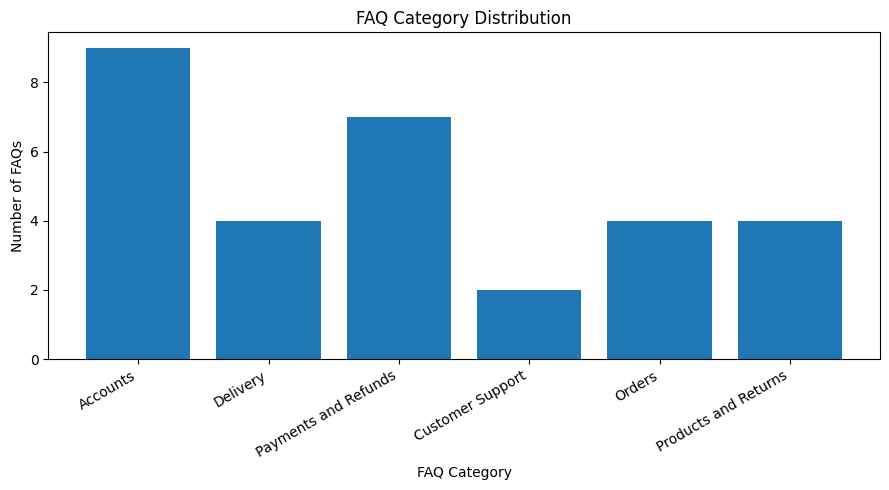

In [ ]:
category_counts = Counter(faq[2] for faq in faqs)

plt.figure(figsize=(9, 5))
plt.bar(category_counts.keys(), category_counts.values())
plt.xlabel("FAQ Category")
plt.ylabel("Number of FAQs")
plt.title("FAQ Category Distribution")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()